# SSD: Single Shot MultiBox Detector

**Paper:** [arXiv:1512.02325](https://arxiv.org/abs/1512.02325)
**Authors:** Wei Liu, Dragomir Anguelov, Dumitru Erhan, Christian Szegedy, Scott Reed, Cheng-Yang Fu, Alexander C. Berg (ECCV 2016)

This notebook builds an SSD-style detector from scratch in PyTorch. SSD predicts boxes in a single forward pass,
like YOLO, but it attaches small convolutional predictors to **several feature maps of decreasing resolution**.
Each feature-map cell owns a fixed set of **default boxes** (anchors) with different scales and aspect ratios, and the
network predicts class scores plus box offsets for every default box.

What is implemented from scratch:
- Multi-scale default box generation (the paper's scale formula `s_k` and aspect ratios `{1, 2, 3, 1/2, 1/3}` + extra `s'_k`)
- The matching strategy (best default box per ground truth + every default box with Jaccard overlap > 0.5)
- Box encoding with variances, the MultiBox loss (Smooth L1 + softmax confidence) and 3:1 hard negative mining
- Per-class NMS inference, VOC-style mAP@0.5, and an analysis of which feature map detects which object sizes

**Simplifications vs. the paper:**
- Synthetic "shapes" dataset (circles, rectangles, triangles at very different sizes) instead of PASCAL VOC / COCO
- 256×256 input and a small VGG-style backbone with BatchNorm trained from scratch, instead of ImageNet-pretrained VGG-16 at 300×300
- AdamW + cosine schedule instead of SGD with step decay; only horizontal-flip augmentation (no random crop / zoom-out)

## 1. Imports & Configuration

In [1]:
import math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torchvision.ops import nms, box_iou

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# --- Data ---
IMG_SIZE = 256
CLASS_NAMES = ['background', 'circle', 'rectangle', 'triangle']
NUM_CLASSES = len(CLASS_NAMES)          # index 0 is background, as in the paper
N_TRAIN, N_VAL = 4000, 500
MIN_OBJ, MAX_OBJ = 16, 170              # object sizes in pixels (log-uniform) -> needs many scales

# --- Default boxes (Section 2.2 of the paper) ---
FMAP_SIZES = [32, 16, 8, 4, 2, 1]       # 6 source feature maps, like SSD300's 38/19/10/5/3/1
ASPECT_RATIOS = [[2], [2, 3], [2, 3], [2, 3], [2], [2]]  # 4 or 6 boxes per location, as in SSD300
S_FIRST, S_MIN, S_MAX = 0.1, 0.2, 0.9   # first map uses 0.1 (paper's conv4_3), the rest are linear in [0.2, 0.9]
ANCHORS_PER_LOC = [2 + 2 * len(ars) for ars in ASPECT_RATIOS]

# --- Training ---
BATCH_SIZE = 32
EPOCHS = 50
LR = 1e-3
WEIGHT_DECAY = 5e-4
IOU_MATCH = 0.5                         # Jaccard threshold for positive matches
NEG_POS_RATIO = 3                       # hard negative mining ratio
VARIANCES = (0.1, 0.2)                  # encoding variances used by the reference implementation

# --- Inference ---
CONF_THRESH = 0.05
NMS_THRESH = 0.45
TOP_K = 100
print('Anchors per location by feature map:', dict(zip(FMAP_SIZES, ANCHORS_PER_LOC)))

Device: cuda
GPU: Tesla T4
Anchors per location by feature map: {32: 4, 16: 6, 8: 6, 4: 6, 2: 4, 1: 4}


## 2. Synthetic Multi-Scale Shapes Dataset

Each 256×256 image has a noisy random background and 1–6 shapes (circle, rectangle, triangle) in random colors.
Object sizes are drawn **log-uniformly from 16 px to 170 px**, so a detector needs both fine feature maps
(for tiny objects) and coarse ones (for objects that fill most of the image) — exactly the problem SSD's
multi-scale design targets. Colors are random and not tied to the class, so the network has to learn shape.

Boxes are stored as normalized `[x1, y1, x2, y2]` in `[0, 1]`, and labels are `1..3` (0 = background).

Built 4000 train / 500 val images in 20.4s
Image tensor: (4000, 3, 256, 256) torch.uint8
Objects: 13942 | size px  min=16  median=47  max=254


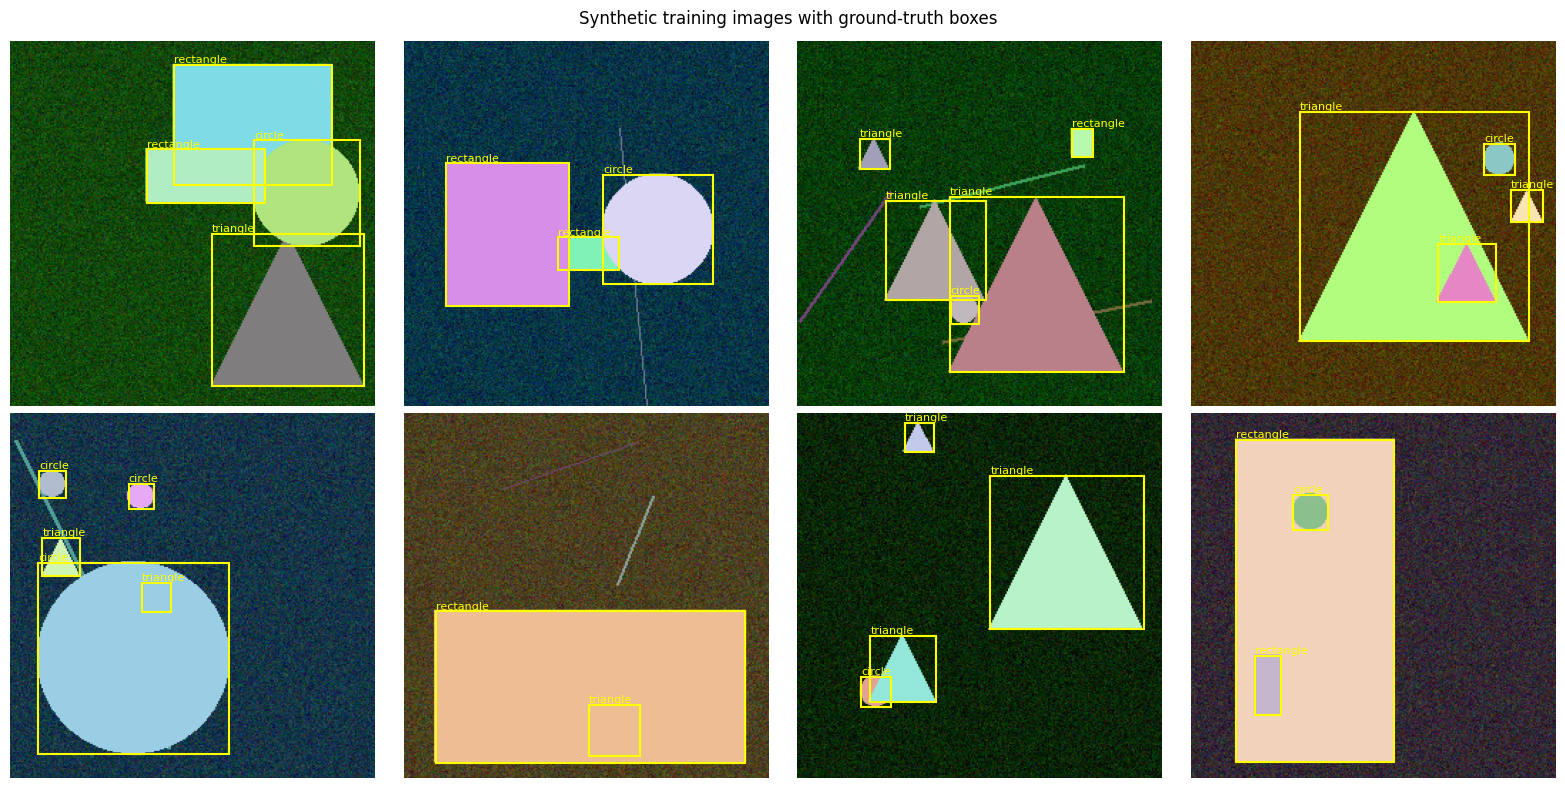

In [2]:
def _box_iou_np(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def make_sample(rng, img_size=IMG_SIZE):
    bg = np.array([rng.randint(0, 90) for _ in range(3)], dtype=np.float32)
    arr = bg + np.random.default_rng(rng.randint(0, 2**31)).normal(0, 18, (img_size, img_size, 3))
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    draw = ImageDraw.Draw(img)

    # A few random distractor lines (not objects) so the background is not trivially flat
    for _ in range(rng.randint(0, 4)):
        pts = [rng.randint(0, img_size) for _ in range(4)]
        draw.line(pts, fill=tuple(rng.randint(60, 160) for _ in range(3)), width=rng.randint(1, 3))

    boxes, labels = [], []
    for _ in range(rng.randint(1, 6)):
        for _attempt in range(20):
            size = math.exp(rng.uniform(math.log(MIN_OBJ), math.log(MAX_OBJ)))
            cls = rng.randint(1, 3)
            if cls == 2:  # rectangles get a random aspect ratio
                ar = math.exp(rng.uniform(math.log(0.4), math.log(2.5)))
                w, h = size * math.sqrt(ar), size / math.sqrt(ar)
            else:
                w = h = size
            w, h = min(w, img_size - 2), min(h, img_size - 2)
            x1 = rng.uniform(0, img_size - w); y1 = rng.uniform(0, img_size - h)
            box = [x1, y1, x1 + w, y1 + h]
            if all(_box_iou_np(box, b) < 0.15 for b in boxes):
                break
        else:
            continue
        color = tuple(rng.randint(120, 255) for _ in range(3))
        if cls == 1:
            draw.ellipse(box, fill=color)
        elif cls == 2:
            draw.rectangle(box, fill=color)
        else:
            draw.polygon([((box[0] + box[2]) / 2, box[1]), (box[0], box[3]), (box[2], box[3])], fill=color)
        boxes.append(box); labels.append(cls)

    boxes = torch.tensor(boxes, dtype=torch.float32) / img_size
    return np.array(img), boxes, torch.tensor(labels, dtype=torch.long)


def build_split(n, seed):
    rng = random.Random(seed)
    imgs = np.empty((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    all_boxes, all_labels = [], []
    for i in range(n):
        imgs[i], b, l = make_sample(rng)
        all_boxes.append(b); all_labels.append(l)
    return torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous(), all_boxes, all_labels


t0 = time.time()
train_imgs, train_boxes, train_labels = build_split(N_TRAIN, seed=1)
val_imgs, val_boxes, val_labels = build_split(N_VAL, seed=2)
print(f'Built {N_TRAIN} train / {N_VAL} val images in {time.time() - t0:.1f}s')
print('Image tensor:', tuple(train_imgs.shape), train_imgs.dtype)

sizes_px = torch.cat([(b[:, 2:] - b[:, :2]).max(1).values for b in train_boxes]) * IMG_SIZE
print(f'Objects: {len(sizes_px)} | size px  min={sizes_px.min():.0f}  median={sizes_px.median():.0f}  max={sizes_px.max():.0f}')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.flat, range(8)):
    ax.imshow(train_imgs[i].permute(1, 2, 0).numpy())
    for b, l in zip(train_boxes[i] * IMG_SIZE, train_labels[i]):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec='yellow', lw=1.5))
        ax.text(b[0], b[1] - 2, CLASS_NAMES[l], color='yellow', fontsize=8)
    ax.axis('off')
plt.suptitle('Synthetic training images with ground-truth boxes')
plt.tight_layout(); plt.show()

## 3. Multi-Scale Default Boxes

For `m` feature maps, the paper sets the scale of the default boxes on map `k` to

$$s_k = s_{min} + \frac{s_{max} - s_{min}}{m - 1}(k - 1), \quad s_{min}=0.2,\ s_{max}=0.9$$

with the first (highest-resolution) map using a smaller scale of 0.1, as SSD300 does for `conv4_3`.
For aspect ratio $a_r$ the box is $w = s_k\sqrt{a_r},\ h = s_k/\sqrt{a_r}$, and one extra square box of scale
$s'_k = \sqrt{s_k s_{k+1}}$ is added. Box centers sit at $\left(\frac{j + 0.5}{f_k}, \frac{i + 0.5}{f_k}\right)$.

The generation order (row, column, then anchor) must match how the prediction heads are flattened —
that is the invariant asserted below and again when the model is built.

In [3]:
def compute_scales(n_maps=len(FMAP_SIZES)):
    rest = [S_MIN + (S_MAX - S_MIN) * k / (n_maps - 2) for k in range(n_maps - 1)]
    return [S_FIRST] + rest


def make_default_boxes(fmap_sizes=FMAP_SIZES, aspect_ratios=ASPECT_RATIOS):
    scales = compute_scales(len(fmap_sizes))
    boxes, layer_ids = [], []
    for k, (f, ars) in enumerate(zip(fmap_sizes, aspect_ratios)):
        s = scales[k]
        s_next = scales[k + 1] if k + 1 < len(scales) else 1.0
        for i in range(f):
            for j in range(f):
                cx, cy = (j + 0.5) / f, (i + 0.5) / f
                loc_boxes = [[cx, cy, s, s], [cx, cy, math.sqrt(s * s_next), math.sqrt(s * s_next)]]
                for ar in ars:
                    r = math.sqrt(ar)
                    loc_boxes += [[cx, cy, s * r, s / r], [cx, cy, s / r, s * r]]
                boxes += loc_boxes
                layer_ids += [k] * len(loc_boxes)
    return torch.tensor(boxes).clamp(0, 1), torch.tensor(layer_ids), scales


def cxcywh_to_xyxy(b):
    return torch.cat([b[..., :2] - b[..., 2:] / 2, b[..., :2] + b[..., 2:] / 2], dim=-1)


def xyxy_to_cxcywh(b):
    return torch.cat([(b[..., :2] + b[..., 2:]) / 2, b[..., 2:] - b[..., :2]], dim=-1)


default_boxes, anchor_layer, SCALES = make_default_boxes()
default_boxes_xyxy = cxcywh_to_xyxy(default_boxes)
expected = sum(f * f * a for f, a in zip(FMAP_SIZES, ANCHORS_PER_LOC))
assert default_boxes.shape[0] == expected, (default_boxes.shape, expected)
NUM_DEFAULTS = default_boxes.shape[0]

print(f'Total default boxes: {NUM_DEFAULTS}')
for k, (f, a, s) in enumerate(zip(FMAP_SIZES, ANCHORS_PER_LOC, SCALES)):
    print(f'  map {k}: {f:2d}x{f:<2d} x {a} anchors = {f * f * a:5d} boxes | scale s_k={s:.3f} (~{s * IMG_SIZE:.0f}px)')

Total default boxes: 6132
  map 0: 32x32 x 4 anchors =  4096 boxes | scale s_k=0.100 (~26px)
  map 1: 16x16 x 6 anchors =  1536 boxes | scale s_k=0.200 (~51px)
  map 2:  8x8  x 6 anchors =   384 boxes | scale s_k=0.375 (~96px)
  map 3:  4x4  x 6 anchors =    96 boxes | scale s_k=0.550 (~141px)
  map 4:  2x2  x 4 anchors =    16 boxes | scale s_k=0.725 (~186px)
  map 5:  1x1  x 4 anchors =     4 boxes | scale s_k=0.900 (~230px)


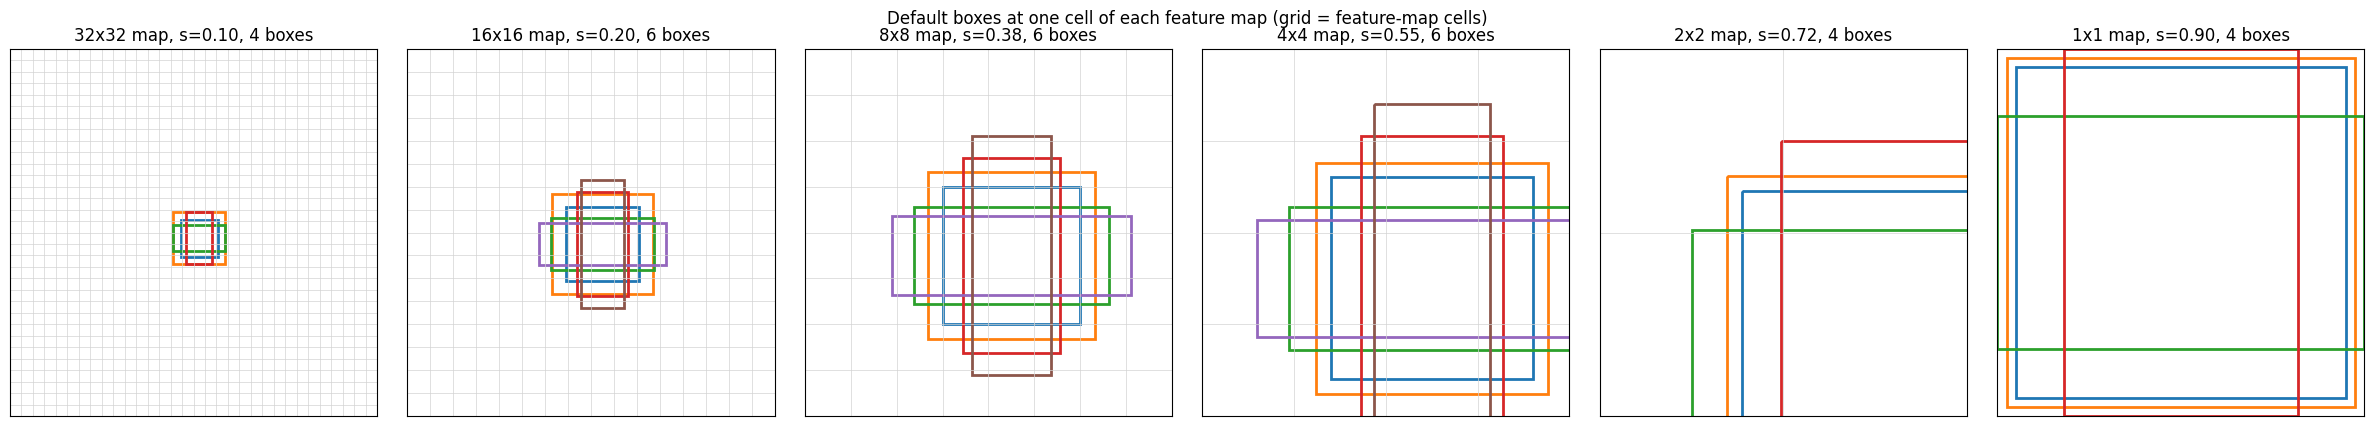

In [4]:
# Visualize the default boxes at one location of every feature map
fig, axes = plt.subplots(1, len(FMAP_SIZES), figsize=(4 * len(FMAP_SIZES), 4.3))
offset = 0
for k, (f, a) in enumerate(zip(FMAP_SIZES, ANCHORS_PER_LOC)):
    ax = axes[k]
    ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect('equal')
    for g in np.linspace(0, 1, f + 1):
        ax.axhline(g, color='lightgray', lw=0.5); ax.axvline(g, color='lightgray', lw=0.5)
    ci = (f // 2) * f + (f // 2)               # a central cell
    loc_boxes = default_boxes_xyxy[offset + ci * a: offset + (ci + 1) * a]
    for n, b in enumerate(loc_boxes):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False,
                                       ec=plt.cm.tab10(n), lw=2))
    ax.set_title(f'{f}x{f} map, s={SCALES[k]:.2f}, {a} boxes')
    ax.set_xticks([]); ax.set_yticks([])
    offset += f * f * a
plt.suptitle('Default boxes at one cell of each feature map (grid = feature-map cells)')
plt.tight_layout(); plt.show()

## 4. Matching Strategy & Box Encoding

During training each ground-truth box is assigned to default boxes (Section 2.2, "Matching strategy"):
1. Match each ground truth to the default box with the **best Jaccard overlap** (guarantees every object has a positive).
2. Then match **every** default box to any ground truth with Jaccard overlap **> 0.5**.

Matched boxes are encoded as offsets relative to the default box $d$ (Equation 2 of the paper, with the
variances used in the reference Caffe code):
$\hat g^{cx} = \frac{g^{cx} - d^{cx}}{v_0 d^{w}},\ \hat g^{w} = \frac{1}{v_1}\log\frac{g^w}{d^w}$ (same for y/h).

In [5]:
def encode(gt_xyxy, defaults_cxcywh, variances=VARIANCES):
    g = xyxy_to_cxcywh(gt_xyxy)
    t_xy = (g[:, :2] - defaults_cxcywh[:, :2]) / (variances[0] * defaults_cxcywh[:, 2:])
    t_wh = torch.log(g[:, 2:] / defaults_cxcywh[:, 2:]) / variances[1]
    return torch.cat([t_xy, t_wh], dim=1)


def decode(loc, defaults_cxcywh, variances=VARIANCES):
    xy = defaults_cxcywh[..., :2] + loc[..., :2] * variances[0] * defaults_cxcywh[..., 2:]
    wh = defaults_cxcywh[..., 2:] * torch.exp(loc[..., 2:] * variances[1])
    return cxcywh_to_xyxy(torch.cat([xy, wh], dim=-1))


def match(gt_boxes, gt_labels, defaults_xyxy, defaults_cxcywh, threshold=IOU_MATCH):
    # Returns encoded loc targets (N, 4) and class targets (N,) with 0 = background
    n = defaults_xyxy.shape[0]
    if gt_boxes.numel() == 0:
        return torch.zeros(n, 4, device=defaults_xyxy.device), torch.zeros(n, dtype=torch.long, device=defaults_xyxy.device)
    iou = box_iou(gt_boxes, defaults_xyxy)               # (G, N)
    best_gt_iou, best_gt_idx = iou.max(dim=0)            # best ground truth for every default box
    best_default_idx = iou.argmax(dim=1)                 # best default box for every ground truth
    # Step 1: force each ground truth onto its best default box
    best_gt_idx[best_default_idx] = torch.arange(gt_boxes.shape[0], device=gt_boxes.device)
    best_gt_iou[best_default_idx] = 2.0
    # Step 2: every default box above the threshold is positive
    labels = gt_labels[best_gt_idx].clone()
    labels[best_gt_iou < threshold] = 0
    loc_t = encode(gt_boxes[best_gt_idx], defaults_cxcywh)
    return loc_t, labels


# Round-trip sanity check: decode(encode(g)) == g
g = torch.tensor([[0.1, 0.2, 0.4, 0.5], [0.5, 0.5, 0.9, 0.7]])
d = default_boxes[[100, 5000]]
assert torch.allclose(decode(encode(g, d), d), g, atol=1e-5)

# Positives per feature map over the training set: shows how object size routes to map scale
pos_per_layer = torch.zeros(len(FMAP_SIZES))
n_pos_total = 0
for b, l in zip(train_boxes[:1000], train_labels[:1000]):
    _, lab = match(b, l, default_boxes_xyxy, default_boxes)
    pos = lab > 0
    pos_per_layer += torch.bincount(anchor_layer[pos], minlength=len(FMAP_SIZES)).float()
    n_pos_total += pos.sum().item()
n_obj = sum(len(l) for l in train_labels[:1000])
print(f'Average positives per object: {n_pos_total / n_obj:.2f} default boxes')
for k, c in enumerate(pos_per_layer):
    print(f'  map {k} ({FMAP_SIZES[k]}x{FMAP_SIZES[k]}): {int(c):6d} positives')

Average positives per object: 7.61 default boxes
  map 0 (32x32):  10219 positives
  map 1 (16x16):   8875 positives
  map 2 (8x8):   5362 positives
  map 3 (4x4):   1694 positives
  map 4 (2x2):    130 positives
  map 5 (1x1):    110 positives


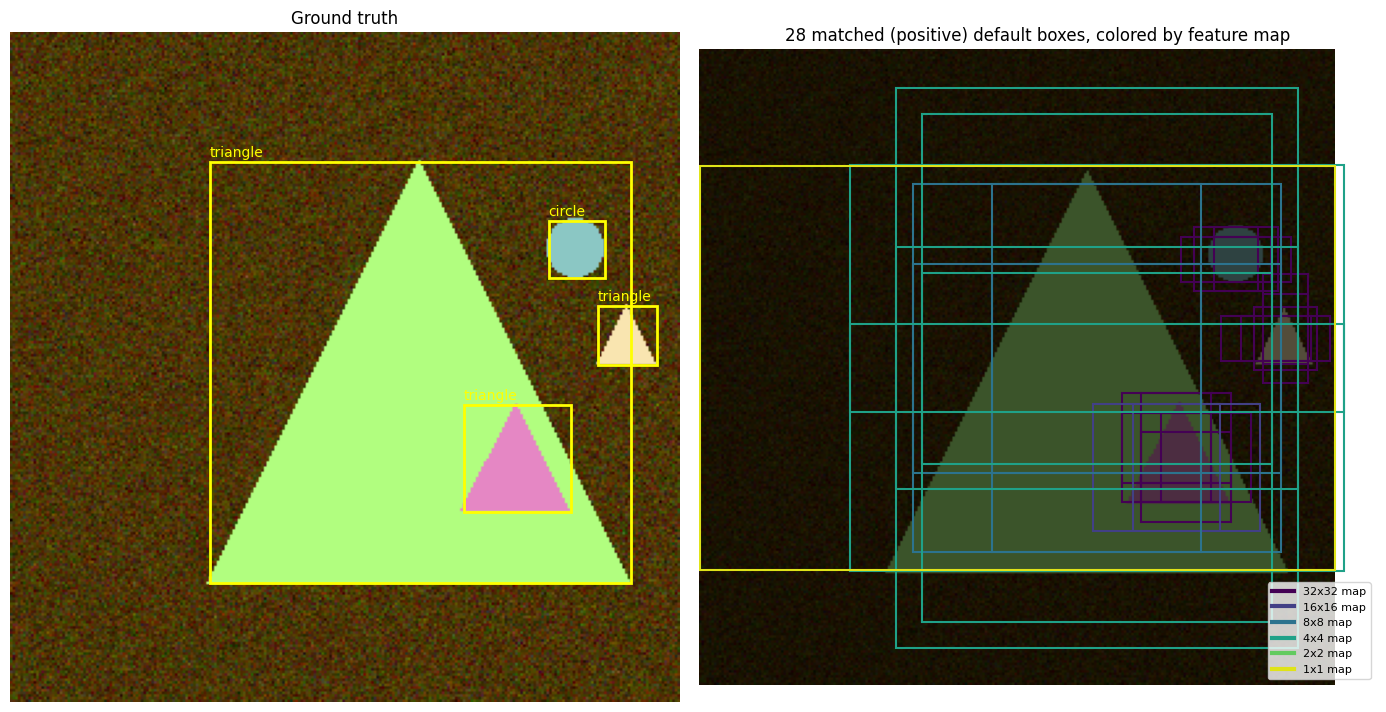

In [6]:
# Visualize which default boxes are matched to each object
idx = 3
img, gtb, gtl = train_imgs[idx], train_boxes[idx], train_labels[idx]
_, lab = match(gtb, gtl, default_boxes_xyxy, default_boxes)
pos = (lab > 0).nonzero().squeeze(1)
layer_colors = plt.cm.viridis(np.linspace(0, 0.95, len(FMAP_SIZES)))

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(img.permute(1, 2, 0).numpy())
for b, l in zip(gtb * IMG_SIZE, gtl):
    ax[0].add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec='yellow', lw=2))
    ax[0].text(b[0], b[1] - 2, CLASS_NAMES[l], color='yellow')
ax[0].set_title('Ground truth'); ax[0].axis('off')
ax[1].imshow(img.permute(1, 2, 0).numpy() // 3)
for p in pos:
    b = default_boxes_xyxy[p] * IMG_SIZE; k = anchor_layer[p].item()
    ax[1].add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=layer_colors[k], lw=1.5))
for k in range(len(FMAP_SIZES)):
    ax[1].plot([], [], color=layer_colors[k], lw=3, label=f'{FMAP_SIZES[k]}x{FMAP_SIZES[k]} map')
ax[1].legend(loc='lower right', fontsize=8)
ax[1].set_title(f'{len(pos)} matched (positive) default boxes, colored by feature map'); ax[1].axis('off')
plt.tight_layout(); plt.show()

## 5. SSD Model

A small VGG-style backbone (with BatchNorm, since we train from scratch) produces a 32×32 map — the analogue of
SSD300's `conv4_3` — which, as in the paper, goes through **L2 normalization with a learnable per-channel scale**
(initialized to 20). A "fc7"-like block and four extra blocks (1×1 reduce → 3×3 stride-2 conv) produce the
16×16, 8×8, 4×4, 2×2 and 1×1 maps. Each of the 6 source maps gets two 3×3 conv predictors:
- localization: `anchors_per_loc × 4` channels
- confidence: `anchors_per_loc × NUM_CLASSES` channels

Outputs are permuted to `(B, H, W, A·k)` and flattened to `(B, H·W·A, k)` so they line up with the default boxes.

In [7]:
def conv_bn(c_in, c_out, k=3, s=1, p=1):
    return nn.Sequential(nn.Conv2d(c_in, c_out, k, s, p, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


class L2Norm(nn.Module):
    def __init__(self, channels, scale=20.0):
        super().__init__()
        self.weight = nn.Parameter(torch.full((channels,), scale))

    def forward(self, x):
        return F.normalize(x, dim=1) * self.weight.view(1, -1, 1, 1)


class SSD(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, anchors_per_loc=ANCHORS_PER_LOC):
        super().__init__()
        self.num_classes = num_classes
        self.base = nn.Sequential(                                   # 256 -> 32
            conv_bn(3, 32), conv_bn(32, 32), nn.MaxPool2d(2),
            conv_bn(32, 64), conv_bn(64, 64), nn.MaxPool2d(2),
            conv_bn(64, 128), conv_bn(128, 128), nn.MaxPool2d(2),
            conv_bn(128, 128), conv_bn(128, 128))
        self.l2norm = L2Norm(128)
        self.fc7 = nn.Sequential(nn.MaxPool2d(2), conv_bn(128, 256), conv_bn(256, 256, 1, 1, 0))  # 16x16
        self.extras = nn.ModuleList([
            nn.Sequential(conv_bn(256, 128, 1, 1, 0), conv_bn(128, 256, 3, 2, 1)),   # 8x8
            nn.Sequential(conv_bn(256, 64, 1, 1, 0), conv_bn(64, 128, 3, 2, 1)),     # 4x4
            nn.Sequential(conv_bn(128, 64, 1, 1, 0), conv_bn(64, 128, 3, 2, 1)),     # 2x2
            nn.Sequential(conv_bn(128, 64, 1, 1, 0), conv_bn(64, 128, 3, 2, 1)),     # 1x1
        ])
        source_channels = [128, 256, 256, 128, 128, 128]
        self.loc_heads = nn.ModuleList([nn.Conv2d(c, a * 4, 3, padding=1) for c, a in zip(source_channels, anchors_per_loc)])
        self.conf_heads = nn.ModuleList([nn.Conv2d(c, a * num_classes, 3, padding=1) for c, a in zip(source_channels, anchors_per_loc)])

    def sources(self, x):
        x = self.base(x)
        feats = [self.l2norm(x)]
        x = self.fc7(x); feats.append(x)
        for block in self.extras:
            x = block(x); feats.append(x)
        return feats

    def forward(self, x):
        locs, confs = [], []
        for f, lh, ch in zip(self.sources(x), self.loc_heads, self.conf_heads):
            locs.append(lh(f).permute(0, 2, 3, 1).reshape(f.shape[0], -1, 4))
            confs.append(ch(f).permute(0, 2, 3, 1).reshape(f.shape[0], -1, self.num_classes))
        return torch.cat(locs, 1), torch.cat(confs, 1)


model = SSD().to(DEVICE).eval()
with torch.no_grad():
    feats = model.sources(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
    loc_out, conf_out = model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
assert [f.shape[-1] for f in feats] == FMAP_SIZES, [f.shape[-1] for f in feats]
assert loc_out.shape[1] == NUM_DEFAULTS, (loc_out.shape, NUM_DEFAULTS)   # heads and default boxes agree
print('Source feature maps:', [tuple(f.shape[1:]) for f in feats])
print('loc output:', tuple(loc_out.shape), '| conf output:', tuple(conf_out.shape))
print(f'Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M')

Source feature maps: [(128, 32, 32), (256, 16, 16), (256, 8, 8), (128, 4, 4), (128, 2, 2), (128, 1, 1)]
loc output: (1, 6132, 4) | conf output: (1, 6132, 4)
Parameters: 1.92M


## 6. MultiBox Loss with Hard Negative Mining

$$L(x, c, l, g) = \frac{1}{N}\left(L_{conf}(x, c) + \alpha L_{loc}(x, l, g)\right), \quad \alpha = 1$$

- $L_{loc}$: Smooth L1 between predicted and encoded offsets, **positives only**.
- $L_{conf}$: softmax cross-entropy over `NUM_CLASSES` (incl. background).
- **Hard negative mining:** almost all ~6k default boxes are background. Instead of using them all, negatives are
  sorted by their confidence loss and only the top ones are kept so that negatives:positives is at most **3:1**.
- $N$ is the number of matched (positive) default boxes in the batch.

In [8]:
def multibox_loss(loc_p, conf_p, loc_t, labels_t, neg_pos_ratio=NEG_POS_RATIO):
    # loc_p: (B, N, 4)  conf_p: (B, N, C)  loc_t: (B, N, 4)  labels_t: (B, N)
    pos = labels_t > 0
    num_pos = pos.sum(dim=1, keepdim=True)
    loc_loss = F.smooth_l1_loss(loc_p[pos], loc_t[pos], reduction='sum')

    ce = F.cross_entropy(conf_p.reshape(-1, conf_p.shape[-1]), labels_t.reshape(-1), reduction='none').view_as(labels_t)
    ce_neg = ce.detach().clone()
    ce_neg[pos] = 0.0                                          # positives are never picked as negatives
    _, order = ce_neg.sort(dim=1, descending=True)
    _, rank = order.sort(dim=1)
    num_neg = torch.clamp(neg_pos_ratio * num_pos, max=pos.shape[1] - 1)
    neg = rank < num_neg
    conf_loss = ce[pos | neg].sum()

    n = num_pos.sum().clamp(min=1).float()
    return loc_loss / n, conf_loss / n

## 7. Training

Images are kept on the GPU as uint8; each batch is normalized, randomly flipped horizontally (boxes flipped too),
then every image is matched against the default boxes. AdamW with a cosine schedule and mixed precision.

In [9]:
defaults_dev = default_boxes.to(DEVICE)
defaults_xyxy_dev = default_boxes_xyxy.to(DEVICE)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1) * 255

train_imgs_dev = train_imgs.to(DEVICE)
val_imgs_dev = val_imgs.to(DEVICE)


def normalize(x_uint8):
    return (x_uint8.float() - MEAN) / STD


def make_targets(boxes_list, labels_list):
    loc_t, lab_t = [], []
    for b, l in zip(boxes_list, labels_list):
        lt, lb = match(b.to(DEVICE), l.to(DEVICE), defaults_xyxy_dev, defaults_dev)
        loc_t.append(lt); lab_t.append(lb)
    return torch.stack(loc_t), torch.stack(lab_t)


@torch.no_grad()
def val_loss(model):
    model.eval()
    tot_l, tot_c, nb = 0.0, 0.0, 0
    for s in range(0, N_VAL, BATCH_SIZE):
        x = normalize(val_imgs_dev[s:s + BATCH_SIZE])
        loc_t, lab_t = make_targets(val_boxes[s:s + BATCH_SIZE], val_labels[s:s + BATCH_SIZE])
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
            loc_p, conf_p = model(x)
        l, c = multibox_loss(loc_p.float(), conf_p.float(), loc_t, lab_t)
        tot_l += l.item(); tot_c += c.item(); nb += 1
    return tot_l / nb, tot_c / nb


model = SSD().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
steps_per_epoch = math.ceil(N_TRAIN / BATCH_SIZE)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=EPOCHS * steps_per_epoch, pct_start=0.05)
scaler = torch.amp.GradScaler(enabled=DEVICE.type == 'cuda')

history = {'loc': [], 'conf': [], 'val_loc': [], 'val_conf': []}
t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(N_TRAIN)
    ep_l, ep_c = 0.0, 0.0
    for s in range(0, N_TRAIN, BATCH_SIZE):
        idx = perm[s:s + BATCH_SIZE]
        if len(idx) < 2:  # BatchNorm on the 1x1 map needs > 1 sample
            continue
        x = train_imgs_dev[idx]
        boxes = [train_boxes[i].clone() for i in idx.tolist()]
        labels = [train_labels[i] for i in idx.tolist()]
        flip = torch.rand(len(idx)) < 0.5
        if flip.any():
            x = x.clone()
            x[flip.to(DEVICE)] = x[flip.to(DEVICE)].flip(-1)
            for j in flip.nonzero().squeeze(1).tolist():
                b = boxes[j]
                boxes[j] = torch.stack([1 - b[:, 2], b[:, 1], 1 - b[:, 0], b[:, 3]], dim=1)
        loc_t, lab_t = make_targets(boxes, labels)

        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
            loc_p, conf_p = model(normalize(x))
        l_loss, c_loss = multibox_loss(loc_p.float(), conf_p.float(), loc_t, lab_t)
        loss = l_loss + c_loss
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        ep_l += l_loss.item(); ep_c += c_loss.item()

    vl, vc = val_loss(model)
    history['loc'].append(ep_l / steps_per_epoch); history['conf'].append(ep_c / steps_per_epoch)
    history['val_loc'].append(vl); history['val_conf'].append(vc)
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f'Epoch {epoch:3d}/{EPOCHS} | train loc {history["loc"][-1]:.3f} conf {history["conf"][-1]:.3f} '
              f'| val loc {vl:.3f} conf {vc:.3f} | {time.time() - t_start:.0f}s')
print(f'Training done in {(time.time() - t_start) / 60:.1f} min')

/tmp/ipykernel_23/2757203503.py:70: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()


Epoch   1/50 | train loc 1.619 conf 5.385 | val loc 0.739 conf 1.972 | 20s


Epoch   5/50 | train loc 0.251 conf 0.807 | val loc 0.304 conf 0.884 | 98s


Epoch  10/50 | train loc 0.172 conf 0.585 | val loc 0.244 conf 0.772 | 196s


Epoch  15/50 | train loc 0.141 conf 0.469 | val loc 0.204 conf 0.701 | 295s


...

Epoch  30/50 | train loc 0.080 conf 0.210 | val loc 0.172 conf 0.742 | 591s


Epoch  35/50 | train loc 0.065 conf 0.154 | val loc 0.168 conf 0.770 | 690s


Epoch  40/50 | train loc 0.054 conf 0.118 | val loc 0.165 conf 0.810 | 789s


Epoch  45/50 | train loc 0.048 conf 0.099 | val loc 0.165 conf 0.827 | 888s


Epoch  50/50 | train loc 0.046 conf 0.094 | val loc 0.166 conf 0.830 | 987s
Training done in 16.4 min


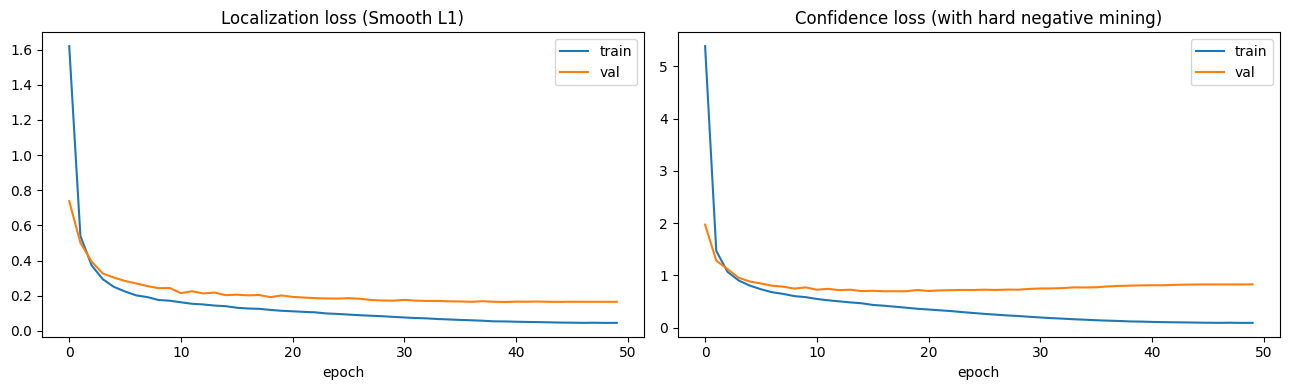

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history['loc'], label='train'); ax[0].plot(history['val_loc'], label='val')
ax[0].set_title('Localization loss (Smooth L1)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history['conf'], label='train'); ax[1].plot(history['val_conf'], label='val')
ax[1].set_title('Confidence loss (with hard negative mining)'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Inference: Decoding + Per-Class NMS

At test time SSD decodes all default boxes, drops low-confidence ones, and runs **non-maximum suppression per class**
(Jaccard 0.45) keeping the top 100 detections per image. We also keep the **index of the source feature map** of
every surviving detection so we can see which scale fired.

In [11]:
@torch.no_grad()
def detect(model, x_uint8, conf_thresh=CONF_THRESH, nms_thresh=NMS_THRESH, top_k=TOP_K):
    model.eval()
    with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
        loc_p, conf_p = model(normalize(x_uint8))
    probs = conf_p.float().softmax(-1)
    boxes_all = decode(loc_p.float(), defaults_dev).clamp(0, 1)
    layer_dev = anchor_layer.to(DEVICE)
    results = []
    for i in range(x_uint8.shape[0]):
        out_b, out_s, out_l, out_k = [], [], [], []
        for c in range(1, NUM_CLASSES):
            sc = probs[i, :, c]
            keep = sc > conf_thresh
            if keep.sum() == 0:
                continue
            b, s, k = boxes_all[i][keep], sc[keep], layer_dev[keep]
            kept = nms(b, s, nms_thresh)
            out_b.append(b[kept]); out_s.append(s[kept]); out_k.append(k[kept])
            out_l.append(torch.full((len(kept),), c, device=DEVICE))
        if out_b:
            b, s, l, k = torch.cat(out_b), torch.cat(out_s), torch.cat(out_l), torch.cat(out_k)
            order = s.argsort(descending=True)[:top_k]
            results.append({'boxes': b[order].cpu(), 'scores': s[order].cpu(), 'labels': l[order].cpu(), 'layers': k[order].cpu()})
        else:
            results.append({'boxes': torch.zeros(0, 4), 'scores': torch.zeros(0), 'labels': torch.zeros(0, dtype=torch.long),
                            'layers': torch.zeros(0, dtype=torch.long)})
    return results


val_dets = []
for s in range(0, N_VAL, 64):
    val_dets += detect(model, val_imgs_dev[s:s + 64])
print(f'Average detections per val image (score > {CONF_THRESH}): {np.mean([len(d["scores"]) for d in val_dets]):.1f}')

Average detections per val image (score > 0.05): 3.9


## 9. Evaluation: VOC-style mAP@0.5

For each class, detections across the validation set are sorted by score and greedily matched to unmatched ground
truths with IoU ≥ 0.5; AP is the area under the (monotone) precision-recall curve.
We also measure **recall by object size** to check that small and large objects are both handled.

  AP[circle   ] = 0.970
  AP[rectangle] = 0.960
  AP[triangle ] = 0.948
mAP@0.5 = 0.959


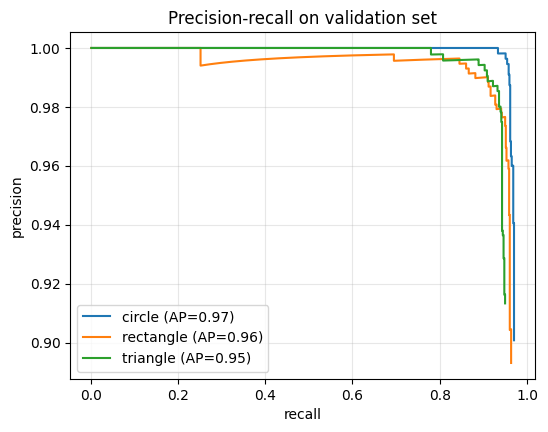

In [12]:
def average_precision(dets, gts_boxes, gts_labels, cls, iou_thr=0.5):
    records = []
    n_gt = 0
    for img_i, (d, gb, gl) in enumerate(zip(dets, gts_boxes, gts_labels)):
        n_gt += (gl == cls).sum().item()
        m = d['labels'] == cls
        for b, s in zip(d['boxes'][m], d['scores'][m]):
            records.append((s.item(), img_i, b))
    if n_gt == 0:
        return float('nan'), None, None
    records.sort(key=lambda r: -r[0])
    used = {i: torch.zeros((gl == cls).sum().item(), dtype=torch.bool) for i, gl in enumerate(gts_labels)}
    tp = np.zeros(len(records)); fp = np.zeros(len(records))
    for r, (_, img_i, b) in enumerate(records):
        g = gts_boxes[img_i][gts_labels[img_i] == cls]
        if len(g) == 0:
            fp[r] = 1; continue
        ious = box_iou(b[None], g)[0]
        j = ious.argmax().item()
        if ious[j] >= iou_thr and not used[img_i][j]:
            tp[r] = 1; used[img_i][j] = True
        else:
            fp[r] = 1
    tp, fp = np.cumsum(tp), np.cumsum(fp)
    recall = tp / n_gt
    precision = tp / np.maximum(tp + fp, 1e-9)
    mrec = np.concatenate([[0], recall, [1]]); mpre = np.concatenate([[0], precision, [0]])
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1])), recall, precision


aps, pr_curves = {}, {}
for c in range(1, NUM_CLASSES):
    ap, rec, prec = average_precision(val_dets, val_boxes, val_labels, c)
    aps[CLASS_NAMES[c]] = ap; pr_curves[CLASS_NAMES[c]] = (rec, prec)
mAP = float(np.mean(list(aps.values())))
for name, ap in aps.items():
    print(f'  AP[{name:9s}] = {ap:.3f}')
print(f'mAP@0.5 = {mAP:.3f}')

plt.figure(figsize=(6, 4.5))
for name, (rec, prec) in pr_curves.items():
    plt.plot(rec, prec, label=f'{name} (AP={aps[name]:.2f})')
plt.xlabel('recall'); plt.ylabel('precision'); plt.title('Precision-recall on validation set'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [13]:
# Recall at score >= 0.5 by object size bucket (largest side in pixels)
SIZE_BUCKETS = [('small  (<32px)', 0, 32), ('medium (32-96px)', 32, 96), ('large  (>96px)', 96, 10_000)]
hit = {name: [0, 0] for name, _, _ in SIZE_BUCKETS}
for d, gb, gl in zip(val_dets, val_boxes, val_labels):
    keep = d['scores'] >= 0.5
    db, dl = d['boxes'][keep], d['labels'][keep]
    for b, l in zip(gb, gl):
        size = (b[2:] - b[:2]).max().item() * IMG_SIZE
        same = db[dl == l]
        found = len(same) > 0 and box_iou(b[None], same).max().item() >= 0.5
        for name, lo, hi in SIZE_BUCKETS:
            if lo <= size < hi:
                hit[name][0] += int(found); hit[name][1] += 1
recall_by_size = {}
for name, (h, n) in hit.items():
    recall_by_size[name] = h / max(n, 1)
    print(f'  recall {name}: {h:4d}/{n:<4d} = {h / max(n, 1):.3f}')

  recall small  (<32px):  476/534  = 0.891
  recall medium (32-96px):  868/899  = 0.966
  recall large  (>96px):  372/374  = 0.995


## 10. Detections Across Feature-Map Scales

The key claim of SSD is that **different feature maps specialize in different object sizes**: high-resolution
early maps with small default boxes catch small objects, coarse late maps catch large ones.
Below, every detection (score ≥ 0.5) is colored by the feature map whose default box produced it.

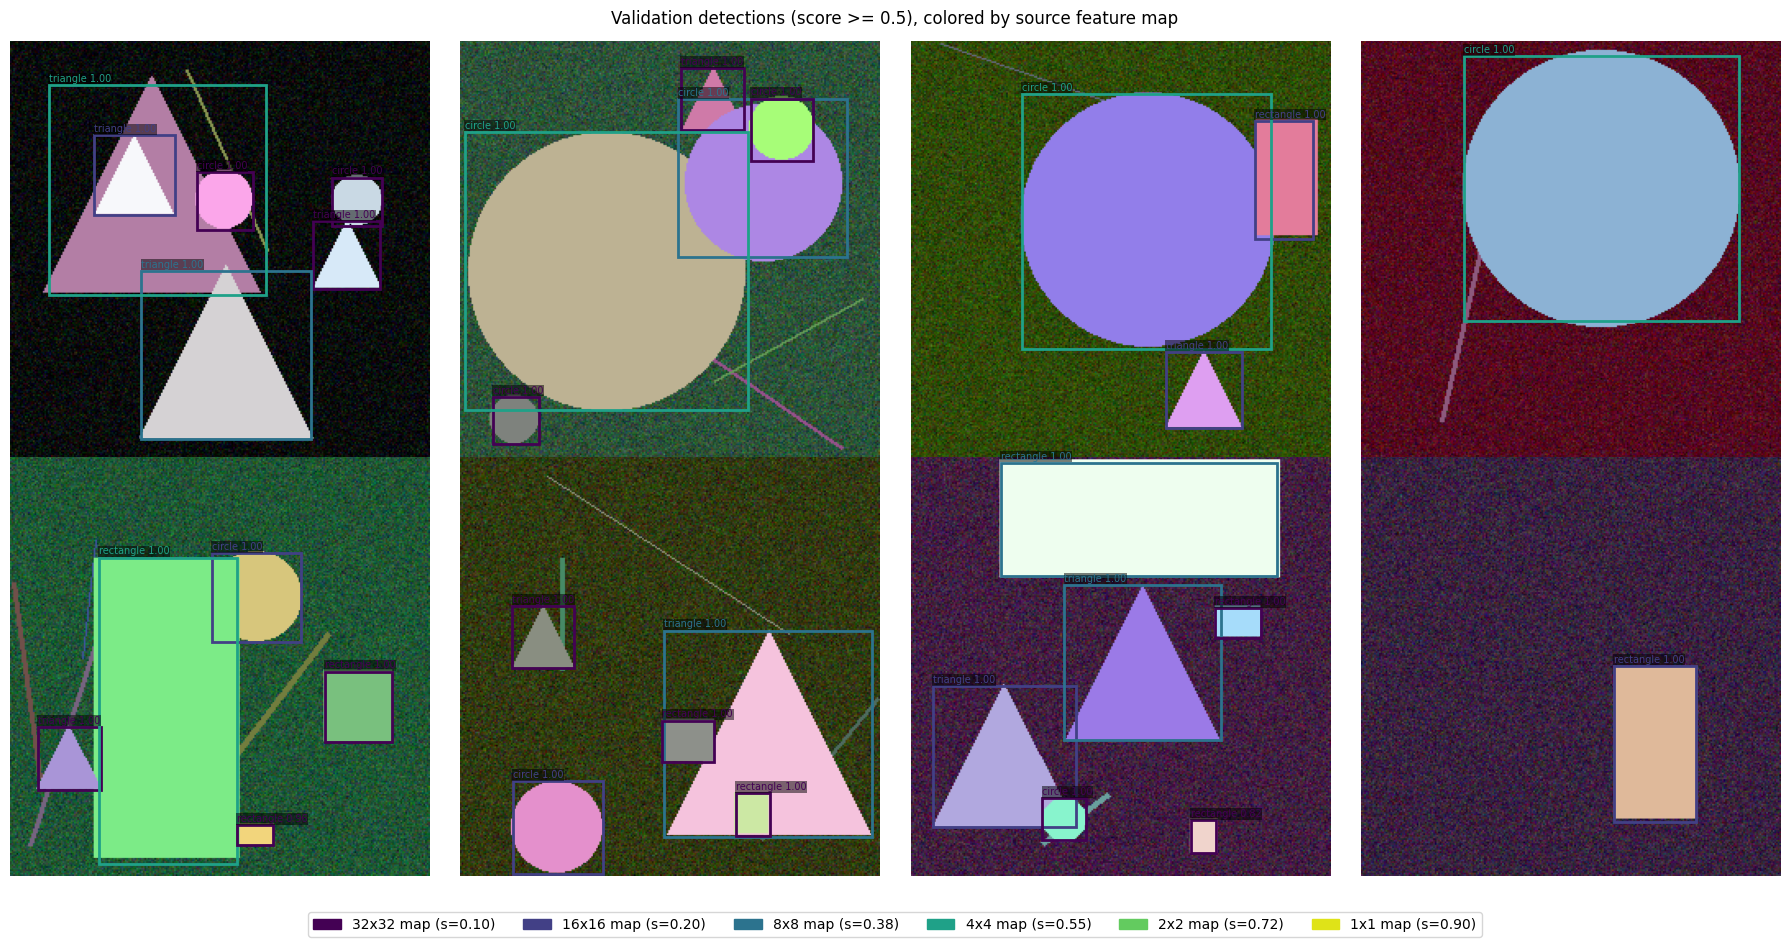

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for ax, i in zip(axes.flat, range(8)):
    ax.imshow(val_imgs[i].permute(1, 2, 0).numpy())
    d = val_dets[i]
    for b, s, l, k in zip(d['boxes'] * IMG_SIZE, d['scores'], d['labels'], d['layers']):
        if s < 0.5:
            continue
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=layer_colors[k], lw=2))
        ax.text(b[0], b[1] - 2, f'{CLASS_NAMES[l]} {s:.2f}', color=layer_colors[k], fontsize=7,
                bbox=dict(facecolor='black', alpha=0.5, pad=0.5, lw=0))
    ax.axis('off')
handles = [patches.Patch(color=layer_colors[k], label=f'{FMAP_SIZES[k]}x{FMAP_SIZES[k]} map (s={SCALES[k]:.2f})')
           for k in range(len(FMAP_SIZES))]
fig.legend(handles=handles, loc='lower center', ncol=len(FMAP_SIZES))
plt.suptitle('Validation detections (score >= 0.5), colored by source feature map')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

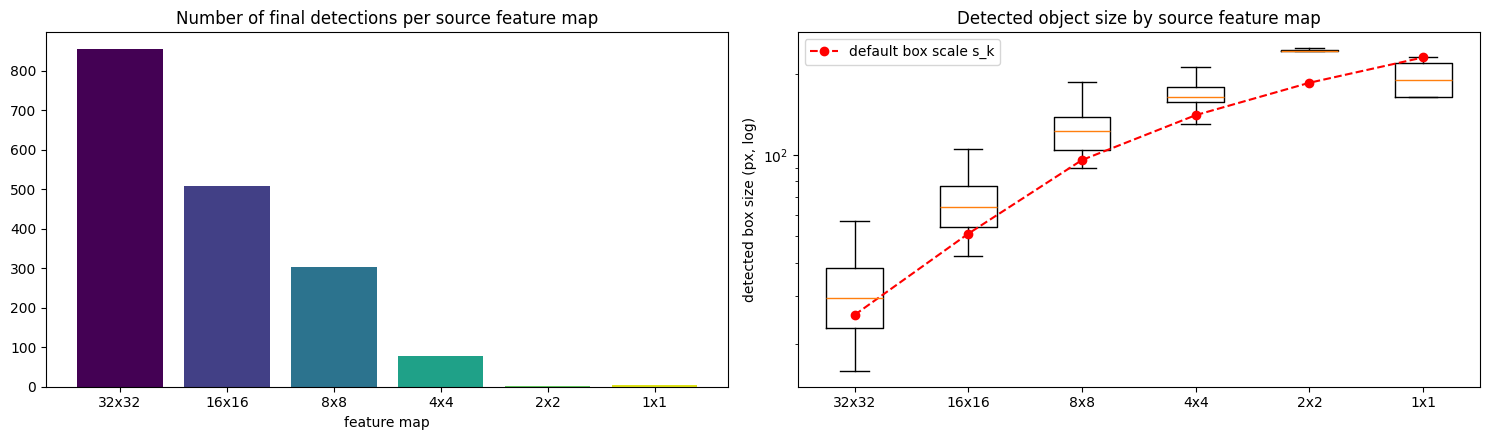

  32x32 map:  854 detections, median size   29.5px
  16x16 map:  509 detections, median size   64.5px
   8x8  map:  303 detections, median size  123.2px
   4x4  map:   77 detections, median size  164.0px
   2x2  map:    3 detections, median size  244.2px
   1x1  map:    5 detections, median size  189.9px


In [15]:
# Which feature map produced detections of which size?
det_sizes = {k: [] for k in range(len(FMAP_SIZES))}
for d in val_dets:
    keep = d['scores'] >= 0.5
    for b, k in zip(d['boxes'][keep], d['layers'][keep]):
        det_sizes[k.item()].append((b[2:] - b[:2]).max().item() * IMG_SIZE)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
counts = [len(det_sizes[k]) for k in range(len(FMAP_SIZES))]
ax[0].bar([f'{f}x{f}' for f in FMAP_SIZES], counts, color=layer_colors)
ax[0].set_title('Number of final detections per source feature map'); ax[0].set_xlabel('feature map')
data = [det_sizes[k] if det_sizes[k] else [np.nan] for k in range(len(FMAP_SIZES))]
ax[1].boxplot(data, showfliers=False)
ax[1].set_xticks(range(1, len(FMAP_SIZES) + 1), [f'{f}x{f}' for f in FMAP_SIZES])
ax[1].plot(range(1, len(FMAP_SIZES) + 1), [s * IMG_SIZE for s in SCALES], 'r--o', label='default box scale s_k')
ax[1].set_yscale('log'); ax[1].set_ylabel('detected box size (px, log)'); ax[1].legend()
ax[1].set_title('Detected object size by source feature map')
plt.tight_layout(); plt.show()
for k in range(len(FMAP_SIZES)):
    if det_sizes[k]:
        print(f'  {FMAP_SIZES[k]:2d}x{FMAP_SIZES[k]:<2d} map: {len(det_sizes[k]):4d} detections, median size {np.median(det_sizes[k]):6.1f}px')

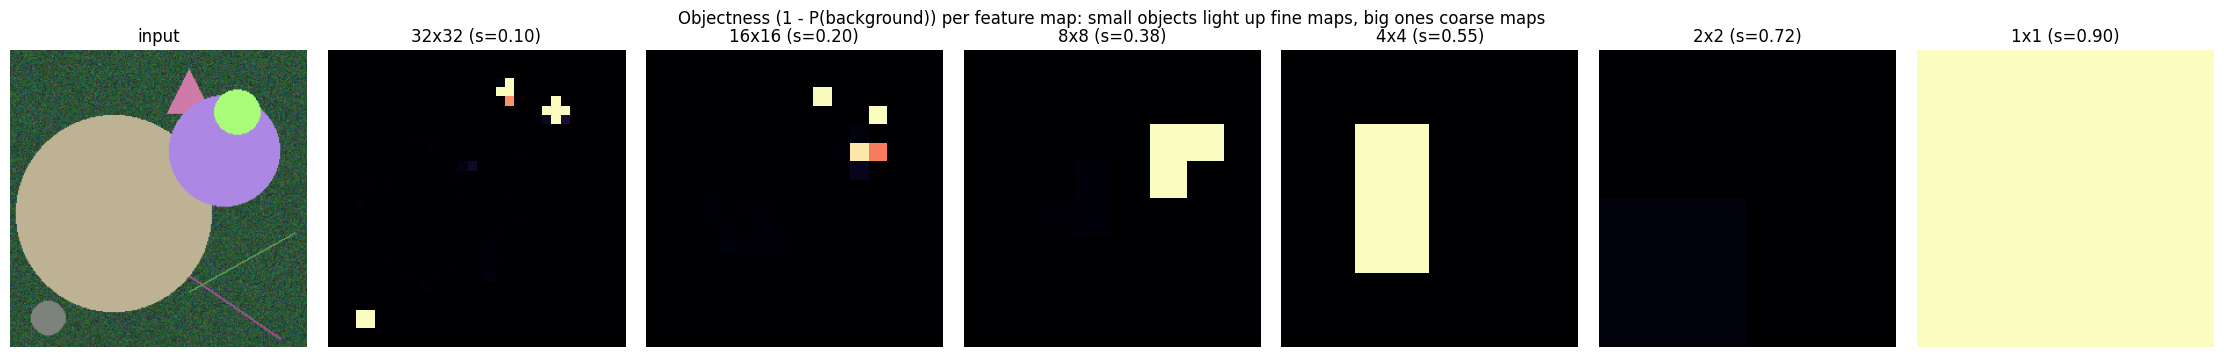

In [16]:
# Per-map confidence heatmaps: max non-background probability at each cell of each feature map
i = 1
with torch.no_grad():
    model.eval()
    _, conf_p = model(normalize(val_imgs_dev[i:i + 1]))
obj = 1 - conf_p.float().softmax(-1)[0, :, 0]
fig, axes = plt.subplots(1, len(FMAP_SIZES) + 1, figsize=(3.2 * (len(FMAP_SIZES) + 1), 3.6))
axes[0].imshow(val_imgs[i].permute(1, 2, 0).numpy()); axes[0].set_title('input'); axes[0].axis('off')
offset = 0
for k, (f, a) in enumerate(zip(FMAP_SIZES, ANCHORS_PER_LOC)):
    m = obj[offset:offset + f * f * a].view(f, f, a).max(-1).values.cpu()
    axes[k + 1].imshow(m, vmin=0, vmax=1, cmap='magma')
    axes[k + 1].set_title(f'{f}x{f} (s={SCALES[k]:.2f})'); axes[k + 1].axis('off')
    offset += f * f * a
plt.suptitle('Objectness (1 - P(background)) per feature map: small objects light up fine maps, big ones coarse maps')
plt.tight_layout(); plt.show()

## 11. Summary

In [17]:
print('=' * 70)
print('SSD: Single Shot MultiBox Detector -- from-scratch reproduction summary')
print('=' * 70)
print(f'Feature maps          : {FMAP_SIZES}')
print(f'Default box scales    : {[round(s, 3) for s in SCALES]}')
print(f'Total default boxes   : {NUM_DEFAULTS}')
print(f'Parameters            : {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M')
print(f'Final val loss        : loc {history["val_loc"][-1]:.3f} | conf {history["val_conf"][-1]:.3f}')
for name, ap in aps.items():
    print(f'AP@0.5 {name:15s}: {ap:.3f}')
print(f'mAP@0.5               : {mAP:.3f}')
for name, r in recall_by_size.items():
    print(f'Recall {name:15s}: {r:.3f}')
print('-' * 70)
print('Each feature map contributes detections in its own size range, which is the core idea of SSD:')
print('multi-scale default boxes on multi-resolution feature maps let one network pass handle all sizes.')

SSD: Single Shot MultiBox Detector -- from-scratch reproduction summary
Feature maps          : [32, 16, 8, 4, 2, 1]
Default box scales    : [0.1, 0.2, 0.375, 0.55, 0.725, 0.9]
Total default boxes   : 6132
Parameters            : 1.92M
Final val loss        : loc 0.166 | conf 0.830
AP@0.5 circle         : 0.970
AP@0.5 rectangle      : 0.960
AP@0.5 triangle       : 0.948
mAP@0.5               : 0.959
Recall small  (<32px) : 0.891
Recall medium (32-96px): 0.966
Recall large  (>96px) : 0.995
----------------------------------------------------------------------
Each feature map contributes detections in its own size range, which is the core idea of SSD:
multi-scale default boxes on multi-resolution feature maps let one network pass handle all sizes.


In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')